# Optimal Trade Execution Under Changing Liquidity

**Group 5:** Ahmad Mohammad, Luciano Handal, Robert Scott

ADSP 32020 Reinforcement Learning · Autumn 2026 · Professor Francisco Azeredo · End-quarter project

**The question.** Does adapting trade sizes to observed liquidity reduce the cost of buying 10 lots within five periods, compared with splitting the order equally (TWAP)?

**The answer.** In the proposed base case, the optimal policy and TWAP coincide. At a high-to-low liquidity ratio of 4, adapting lowers expected cost by 4.95%, but can still cost more on an individual path.

**Presentation route (20 minutes).** The notebook contains the complete implementation; supporting code starts collapsed and its outputs remain visible. The speaking route and technical questions are in `presentation_notes.md`.

| Section | Content | Time |
|---|---|---|
| 1 | Problem description | 2 min |
| 2 | Environment description | 3 min |
| 3 and 4.1 | Method and convergence | 4 min |
| 4.2–4.6 | Policy, baselines, sensitivity and risk | 7 min |
| 5 | Agent demonstration | 2 min |
| 6 and 7 | Requirements and conclusions | 2 min |

In [1]:
from dataclasses import dataclass, replace
from importlib.metadata import version
from itertools import product
from pathlib import Path
import math
import platform

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from IPython.display import display

SEED = 32020           # seed for every random draw in this notebook (the course number)
N_PATHS = 10_000       # simulated liquidity paths
TOL = 1e-8             # stopping tolerance of value iteration
LOW, HIGH = 0, 1       # index of the liquidity regime
REGIME = ("low", "high")

DATA, RESULTS = Path("data"), Path("results")
FIGURES = RESULTS / "figures"
for folder in (DATA, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# The same color for the same policy in every figure, and four decimals in every table.
POLICY_COLOR = {"optimal": "tab:blue", "TWAP": "tab:orange", "buy all at once": "tab:green"}
pd.options.display.float_format = "{:,.4f}".format


def finish(fig, name):
    """Save a figure under results/figures and show it."""
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## 1. Problem description

**Splitting a large order reduces its market impact. Can reacting to liquidity improve on an equal split?** A trader must buy 10 equal lots within five periods. Each trade has a temporary impact cost that grows quadratically with its size and falls with observed liquidity. The price is constant, so the model isolates liquidity effects.

**Background.** Bertsimas and Lo (1998) formulate execution as a stochastic dynamic program; our Week 5 lab studies equal splitting and a response to predictive information. Almgren and Chriss (2001) distinguish temporary and permanent impact and incorporate price risk. Almgren (2012) and Cheridito and Sepin (2014) study stochastic liquidity. Nevmyvaka, Feng and Kearns (2006) use reinforcement learning with time and remaining inventory among the state variables.

**Our contribution relative to the lab.** We replace the price signal with an observed two-state liquidity regime, use whole-lot trades and a temporary quadratic cost, and solve the resulting finite MDP exactly. We retain the equal-split and immediate-purchase baselines and compare all policies on the same 10,000 simulated paths. The Week 5 lab and the Rao–Jelvis order-execution example named in the proposal provide conceptual background; the model and tabular implementation here are specific to this project.

Full citations are in References.

## 2. Environment description

**The environment is fully specified; nothing is estimated from market data.** These are the parameters of the proposal.

| Element | Definition |
|---|---|
| Decision state | $(\tau,q,l)$: periods remaining $\tau\in\{1,\ldots,5\}$, lots remaining $q\in\{1,\ldots,10\}$, regime $l\in\{\text{low},\text{high}\}$ with $L_{\text{low}}=1$ and $L_{\text{high}}=2$ |
| Start | $\tau=5$, $q=10$, low or high regime with probability $0.5$ each |
| Action | Buy an integer $a\in\{0,\ldots,q\}$; at $\tau=1$ the only legal action is $a=q$ |
| Reward | $r=-a^2/L_l$, minus temporary market-impact cost in normalized units |
| Transition | $q'=q-a$, $\tau'=\tau-1$; if the order is unfinished, liquidity stays with probability $0.8$ and switches with probability $0.2$, independently of the trade |
| Terminal condition | Stop immediately when $q=0$. The forced final trade ensures completion by period five. Terminal value is $0$ |

Within a period the trader observes the current regime, trades and pays at that liquidity, and then the regime moves **only if the order is unfinished**. An episode has at most five trades and four regime moves; buying everything immediately ends it after one trade.

There are $5\times10\times2=100$ decision states. The tables also store zero values/actions for $q=0$, giving 110 entries over positive horizons. Arrays of shape `(6, 11, 2)` contain 132 entries because they additionally include a zero terminal layer at `tau=0`; entries with `tau=0, q>0` are padding, not reachable states. Terminal observations have `q=0` and may have positive `tau` after early completion, or `tau=0` after the final trade.

The next cell defines the shared parameters, transition matrix, cost and legal actions.

In [2]:
@dataclass(frozen=True)
class ExecutionParams:
    """Everything that defines one version of the problem."""
    n_lots: int = 10                 # lots to buy
    n_periods: int = 5               # trading periods
    liquidity: tuple = (1.0, 2.0)    # liquidity L in the low and in the high regime
    persistence: float = 0.8         # probability that the regime is the same next period


BASE = ExecutionParams()             # the base case of our proposal


def liquidity_matrix(params):
    """Transition matrix of the regime: M[l, l'] = P(next regime is l' | regime is l)."""
    p = params.persistence
    return np.array([[p, 1 - p], [1 - p, p]])


def trade_cost(a, l, params):
    """Cost of buying a lots in regime l: a^2 / L_l. The reward is minus this cost."""
    return a ** 2 / np.asarray(params.liquidity)[l]


def legal_actions(tau, q):
    """Trades allowed with tau periods and q lots left: 0..q, or exactly q in the last period."""
    return np.array([q]) if tau == 1 else np.arange(q + 1)


print("regime transition matrix (rows: low, high now; columns: low, high next):")
print(liquidity_matrix(BASE))
print("cost of buying 2 lots: low", trade_cost(2, LOW, BASE), "| high", trade_cost(2, HIGH, BASE))
print("legal trades with 3 lots left: 4 periods to go", legal_actions(4, 3),
      "| last period", legal_actions(1, 3))

regime transition matrix (rows: low, high now; columns: low, high next):
[[0.8 0.2]
 [0.2 0.8]]
cost of buying 2 lots: low 4.0 | high 2.0
legal trades with 3 lots left: 4 periods to go [0 1 2 3] | last period [3]


### 2.1 The Gymnasium environment

**The same model as a Gymnasium environment**, with the `reset` and `step` interface used throughout the course.

- **Observation:** the array `[tau, q, l]`, in the space `MultiDiscrete([6, 11, 2])`.
- **Action:** the number of lots to buy, in the space `Discrete(11)`. `info["action_mask"]` marks the trades that are legal in the current state.
- **Illegal trades** raise an error; they are not silently corrected.
- **Randomness:** `reset(seed=...)` seeds the regime draws. `reset(options={"liquidity_path": ...})` replays a given sequence of regimes instead, so that different policies can face the same liquidity.

Value iteration does not need this class: it works directly on the model functions above. We use the environment for the demonstration in section 5 and to check the simulator in section 4.3. `rollout` runs one episode with a policy table and returns the log.

In [3]:
class TradeExecutionEnv(gym.Env):
    """Buy n_lots within n_periods. Observation [tau, q, l]; the action is the number of lots to buy now."""

    def __init__(self, params=BASE):
        self.params = params
        self.observation_space = spaces.MultiDiscrete([params.n_periods + 1, params.n_lots + 1, 2])
        self.action_space = spaces.Discrete(params.n_lots + 1)

    def _observation(self):
        return np.array([self.tau, self.q, self.l])

    def _info(self):
        mask = np.zeros(self.params.n_lots + 1, dtype=np.int8)  # 1 marks a legal trade
        if self.q > 0:
            mask[legal_actions(self.tau, self.q)] = 1
        return {"action_mask": mask}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.path = (options or {}).get("liquidity_path")       # optional pre-set regimes, one per period
        self.tau, self.q = self.params.n_periods, self.params.n_lots
        self.l = int(self.path[0]) if self.path is not None else int(self.np_random.integers(2))
        return self._observation(), self._info()

    def step(self, action):
        action = int(action)
        if self.q == 0:
            raise RuntimeError("the episode is over; call reset()")
        if action not in legal_actions(self.tau, self.q):
            raise ValueError(f"illegal trade {action} with tau={self.tau}, q={self.q}")
        cost = float(trade_cost(action, self.l, self.params))   # paid at the liquidity seen before trading
        self.q -= action
        self.tau -= 1
        terminated = self.q == 0
        if not terminated:                                      # only then does liquidity move
            if self.path is not None:
                self.l = int(self.path[self.params.n_periods - self.tau])
            elif self.np_random.random() >= self.params.persistence:
                self.l = 1 - self.l
        # Written as 0.0 - cost so that buying nothing gives a reward of 0.0, not -0.0.
        reward = 0.0 - cost
        return self._observation(), reward, terminated, False, self._info()


def rollout(env, policy, liquidity_path=None, seed=None):
    """Run one episode with a policy table policy[tau, q, l] and return the step-by-step log."""
    obs, info = env.reset(seed=seed, options={"liquidity_path": liquidity_path})
    log, terminated = [], False
    while not terminated:
        tau, q, l = obs
        obs, reward, terminated, truncated, info = env.step(policy[tau, q, l])
        log.append({"period": env.params.n_periods - tau + 1, "liquidity": REGIME[l], "lots left": q,
                    "trade": policy[tau, q, l], "cost": abs(reward)})
    return pd.DataFrame(log)

In [4]:
env = TradeExecutionEnv(BASE)
check_env(env, skip_render_check=True)           # Gymnasium's own test of the reset/step interface
print("passes Gymnasium's environment checker")
print("observation space:", env.observation_space, "| action space:", env.action_space)

obs, info = env.reset(seed=SEED)
print(f"\nreset: observation [tau, q, l] = {obs} | legal trades {np.flatnonzero(info['action_mask'])}")
for trade in (3, 0, 4, 1, 2):                    # a hand-picked schedule, only to show the mechanics
    obs, reward, terminated, truncated, info = env.step(trade)
    print(f"buy {trade}: reward {reward:5.1f} | observation {obs} | terminated {terminated} | "
          f"legal next {np.flatnonzero(info['action_mask'])}")

env.reset(seed=SEED)
env.step(4)
env.step(4)
try:
    env.step(5)                                  # only 2 lots are left
except ValueError as error:
    print("\nrejected:", error)

passes Gymnasium's environment checker
observation space: MultiDiscrete([ 6 11  2]) | action space: Discrete(11)

reset: observation [tau, q, l] = [ 5 10  0] | legal trades [ 0  1  2  3  4  5  6  7  8  9 10]
buy 3: reward  -9.0 | observation [4 7 0] | terminated False | legal next [0 1 2 3 4 5 6 7]
buy 0: reward   0.0 | observation [3 7 0] | terminated False | legal next [0 1 2 3 4 5 6 7]
buy 4: reward -16.0 | observation [2 3 1] | terminated False | legal next [0 1 2 3]
buy 1: reward  -0.5 | observation [1 2 1] | terminated False | legal next [2]
buy 2: reward  -2.0 | observation [0 0 1] | terminated True | legal next []

rejected: illegal trade 5 with tau=3, q=2


**The walkthrough shows the mechanics.** Buying 3 lots in low liquidity costs $3^2/1=9$; buying 1 in high liquidity costs $1^2/2=0.5$. The regime moves after an unfinished trade. With one period left the remaining 2 lots are forced, and an attempt to buy 5 when only 2 remain raises an error.

**Model simplifications.** The price is constant, so there is no price risk or forecast. Timing still responds to observed liquidity, convex impact and the deadline. Impact is known, temporary and quadratic; liquidity has two perfectly observed levels, known transition probabilities and no response to our trades. Costs are normalized rather than calibrated to an order book. These choices isolate one mechanism and make exact solution possible.

## 3. Solution method

**We solve the MDP with synchronous value iteration.** Let $V(\tau, q, l)$ be the value of the state: minus the lowest expected cost of buying the remaining $q$ lots in $\tau$ periods, starting in regime $l$. It satisfies the Bellman equation

$$V(\tau, q, l) = \max_{a \in A(\tau, q)} \Big[ -\frac{a^2}{L_l} + \sum_{l'} P(l' \mid l) V(\tau - 1, q - a, l') \Big], \qquad V(0, \cdot, \cdot) = 0,$$

where $A(\tau, q) = \lbrace 0, \dots, q \rbrace$ for $\tau > 1$ and $A(1, q) = \lbrace q \rbrace$.

**Implementation.**

- **Tables.** $V$ and the policy are arrays indexed `[tau, q, l]` of shape `(6, 11, 2)`. Layer `tau = 0` holds the terminal value $0$.
- **One sweep.** `bellman_backup` applies the right-hand side of the Bellman equation to every state and reads only the table from the previous sweep, which is what makes the iteration synchronous. The loops run over $\tau$, $q$ and $l$, and the trades $a$ are handled as one vector, so the line that fills `Q` is the Bellman equation.
- **Parameters.** The discount factor is 1, because the horizon is five periods and costs are not discounted. The initial table is zero.
- **Stopping rule.** The iteration stops when the largest absolute change of any state value in a sweep is below $10^{-8}$.
- **Ties.** If two trades have the same value, the policy takes the smaller one (the smallest trade within $10^{-9}$ of the best), so the result does not depend on rounding noise.

**Why it stops although the discount factor is 1.** Every transition lowers $\tau$ by one, so no state is visited twice. The first sweep makes the states with one period left exact, the second those with two periods left, and so on. After five sweeps the table is exact, and the sixth sweep changes nothing.

In [5]:
def bellman_backup(V, params):
    """One synchronous sweep over every state, using only the old table V[tau, q, l].
    Returns the new table and Q[tau, q, l, a], the value of each trade (-inf where the trade is illegal)."""
    T, N = params.n_periods, params.n_lots
    M = liquidity_matrix(params)
    Q = np.full((T + 1, N + 1, 2, N + 1), -np.inf)
    for tau in range(1, T + 1):
        for q in range(N + 1):
            a = legal_actions(tau, q)
            for l in (LOW, HIGH):
                expected_next = V[tau - 1, q - a] @ M[l]              # E[ V(tau - 1, q - a, l') | l ]
                Q[tau, q, l, a] = -trade_cost(a, l, params) + expected_next
    V_new = np.zeros_like(V)
    V_new[1:] = Q[1:].max(axis=-1)
    return V_new, Q


def value_iteration(params, tol=TOL):
    """Synchronous value iteration from V = 0 with discount factor 1.
    Returns V[tau, q, l], the greedy policy[tau, q, l] and the list of tables after every sweep."""
    V = np.zeros((params.n_periods + 1, params.n_lots + 1, 2))
    sweeps = [V]
    while True:
        V, Q = bellman_backup(V, params)
        sweeps.append(V)
        if np.abs(sweeps[-1] - sweeps[-2]).max() < tol:
            break
    near_best = Q[1:] >= V[1:, :, :, None] - 1e-9      # True for every trade within 1e-9 of the best one
    policy = np.zeros(V.shape, dtype=int)
    policy[1:] = np.argmax(near_best, axis=-1)         # position of the first True: the smallest such trade
    return V, policy, sweeps


def expected_cost(V, params):
    """Expected cost of the whole order: minus the start value, averaged over the 50/50 initial regime."""
    return -V[params.n_periods, params.n_lots].mean()


V, policy, sweeps = value_iteration(BASE)
changes = [np.abs(new - old).max() for old, new in zip(sweeps, sweeps[1:])]
print(f"value iteration stopped after {len(changes)} sweeps")
print("largest value change in each sweep:", np.round(changes, 4))
print(f"value at the start: low {V[5, 10, LOW]:.4f} | high {V[5, 10, HIGH]:.4f}")
print(f"expected cost of the order under the computed policy: {expected_cost(V, BASE):.4f}")

value iteration stopped after 6 sweeps
largest value change in each sweep: [100.      47.5     30.4     22.216   17.3056   0.    ]
value at the start: low -17.3056 | high -12.6944
expected cost of the order under the computed policy: 15.0000


## 4. Results and policy analysis

### 4.1 Convergence of value iteration

The left panel shows the quantity behind the stopping rule, the largest change in $V$ in each sweep. The right panel and the table follow one family of states across the sweeps: 10 lots in low liquidity, for each number of periods remaining.

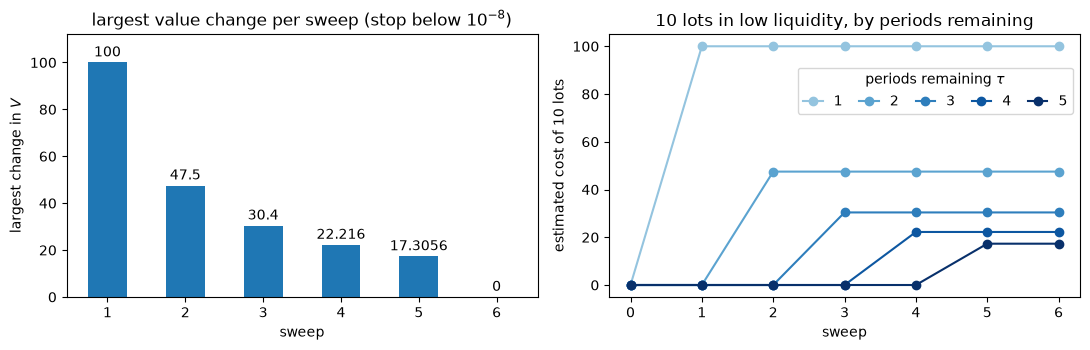

,tau = 1,tau = 2,tau = 3,tau = 4,tau = 5
after sweep,,,,,
0,0.0000,0.0000,0.0000,0.0000,0.0000
1,100.0000,0.0000,0.0000,0.0000,0.0000
2,100.0000,47.5000,0.0000,0.0000,0.0000
3,100.0000,47.5000,30.4000,0.0000,0.0000
4,100.0000,47.5000,30.4000,22.2160,0.0000
5,100.0000,47.5000,30.4000,22.2160,17.3056
6,100.0000,47.5000,30.4000,22.2160,17.3056


In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))

sweep_numbers = np.arange(1, len(changes) + 1)
bars = left.bar(sweep_numbers, changes, width=0.5)
left.bar_label(bars, padding=2)
left.set(xlabel="sweep", ylabel="largest change in $V$", ylim=(0, 112),
         title=r"largest value change per sweep (stop below $10^{-8}$)")

for tau in range(1, 6):
    right.plot(range(len(sweeps)), [abs(table[tau, 10, LOW]) for table in sweeps], marker="o",
               color=plt.cm.Blues(0.25 + 0.15 * tau), label=str(tau))      # more periods: darker blue
right.set(xlabel="sweep", ylabel="estimated cost of 10 lots",
          title="10 lots in low liquidity, by periods remaining")
right.legend(title=r"periods remaining $\tau$", ncol=5, loc="upper right", bbox_to_anchor=(1, 0.9),
             columnspacing=1.2, handlelength=1.4)
finish(fig, "convergence")

display(pd.DataFrame([np.abs(table[1:, 10, LOW]) for table in sweeps],
                     index=pd.Index(range(len(sweeps)), name="after sweep"),
                     columns=[f"tau = {tau}" for tau in range(1, 6)]))

**Five sweeps determine the values; the sixth confirms convergence.** The largest changes are 100, 47.5, 30.4, 22.216, 17.3056 and finally 0, below $10^{-8}$. The start values are $-17.3056$ in low liquidity and $-12.6944$ in high liquidity, giving expected cost 15.

Each sweep settles one additional horizon layer. The right panel and table show that the state with $\tau$ periods left reaches its exact value in sweep $\tau$. The plotted change is the stopping metric, not an estimated distance to an unknown optimum. Because every transition reduces time, a discount factor of 1 causes no infinite-horizon convergence problem.

### 4.2 The computed policy and its value

The two grids show the computed policy, one grid per liquidity regime. Each cell is one state, and the number in it is the lots to buy in that state.

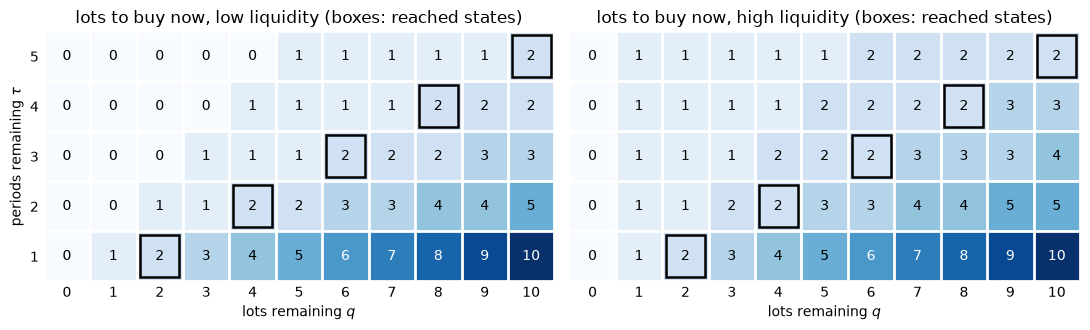

low liquidity:  the policy buys floor(q / tau) in every state: True
high liquidity: the policy buys ceil(q / tau) in every state:  True
states where the two regimes trade differently: 28 of 55
states reached from the start (tau, q): [(5, 10), (4, 8), (3, 6), (2, 4), (1, 2)]


In [7]:
def reached_states(policy, params):
    """States [tau, q, l] visited from the start under the policy, over every possible liquidity path."""
    reached = np.zeros(policy.shape, dtype=bool)
    for path in product((LOW, HIGH), repeat=params.n_periods):
        q = params.n_lots
        for t, l in enumerate(path):
            if q == 0:
                break
            tau = params.n_periods - t
            reached[tau, q, l] = True
            q -= policy[tau, q, l]
    return reached


def draw_grid(ax, table, title, vmax, outline):
    """Colored grid of lots, one cell per (lots remaining, periods remaining).
    Cells with a box are the states reached from the start."""
    n_tau, n_q = table.shape[0] - 1, table.shape[1]
    ax.imshow(table[1:], cmap="Blues", vmin=0, vmax=vmax, origin="lower", aspect="auto",
              extent=(-0.5, n_q - 0.5, 0.5, n_tau + 0.5))
    for tau, q in product(range(1, n_tau + 1), range(n_q)):
        text_color = "white" if table[tau, q] > vmax / 2 else "black"
        ax.text(q, tau, table[tau, q], ha="center", va="center", color=text_color)
        if outline[tau, q]:
            box = plt.Rectangle((q - 0.42, tau - 0.42), 0.84, 0.84, fill=False, linewidth=1.8)
            ax.add_patch(box)
    ax.set(xticks=range(n_q), yticks=range(1, n_tau + 1), title=title, xlabel="lots remaining $q$")
    ax.set_xticks(np.arange(-0.5, n_q), minor=True)
    ax.set_yticks(np.arange(0.5, n_tau + 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.spines[:].set_visible(False)


reached = reached_states(policy, BASE)
reached_pairs = [(tau, q) for tau in range(5, 0, -1) for q in range(10, -1, -1) if reached[tau, q].any()]
assert reached_pairs == [(5, 10), (4, 8), (3, 6), (2, 4), (1, 2)]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for l, ax in zip((LOW, HIGH), axs):
    title = f"lots to buy now, {REGIME[l]} liquidity (boxes: reached states)"
    draw_grid(ax, policy[:, :, l], title,
              vmax=BASE.n_lots, outline=reached[:, :, l])
axs[0].set_ylabel(r"periods remaining $\tau$")
finish(fig, "policy")

tau_column, q_row = np.arange(1, 6)[:, None], np.arange(11)[None, :]
print("low liquidity:  the policy buys floor(q / tau) in every state:",
      np.array_equal(policy[1:, :, LOW], np.floor(q_row / tau_column)))
print("high liquidity: the policy buys ceil(q / tau) in every state: ",
      np.array_equal(policy[1:, :, HIGH], np.ceil(q_row / tau_column)))
print("states where the two regimes trade differently:",
      int((policy[1:, :, LOW] != policy[1:, :, HIGH]).sum()), "of", policy[1:, :, LOW].size)
print("states reached from the start (tau, q):", reached_pairs)

**The reached states prescribe 2 lots in either regime.** The boxes trace $(\tau,q)=(5,10),(4,8),(3,6),(2,4),(1,2)$.

Elsewhere, the base-case policy buys $\lfloor q/\tau\rfloor$ in low liquidity and $\lceil q/\tau\rceil$ in high liquidity. The regimes differ in 28 of the 55 tabulated $(\tau,q)$ pairs, but only when $q$ is not divisible by $\tau$. Starting at $q=2\tau$, trading 2 preserves that equality. Thus regime dependence in the full policy map does not imply a benefit from this start state. The bottom row always buys everything left.

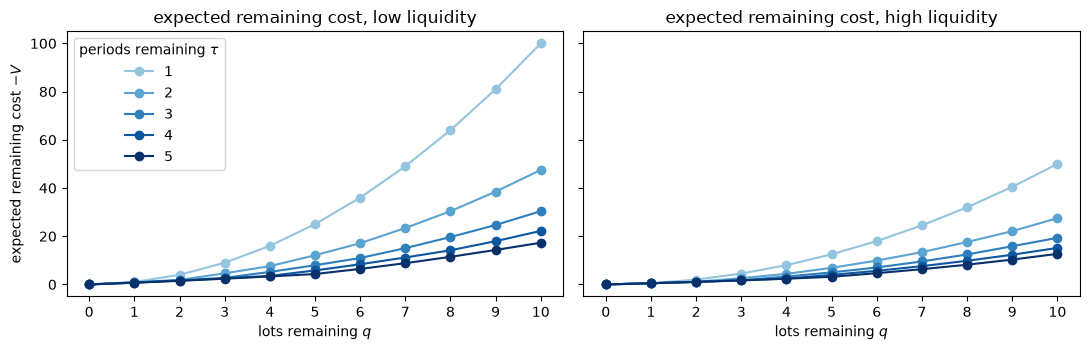

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for l, ax in zip((LOW, HIGH), axs):
    for tau in range(1, 6):
        ax.plot(range(11), -V[tau, :, l], marker="o", color=plt.cm.Blues(0.25 + 0.15 * tau), label=str(tau))
    ax.set(xlabel="lots remaining $q$", xticks=range(11),
           title=f"expected remaining cost, {REGIME[l]} liquidity")
axs[0].set_ylabel("expected remaining cost $-V$")
axs[0].legend(title=r"periods remaining $\tau$", loc="upper left")
finish(fig, "value_function")

**More inventory increases cost; more time reduces it.** The curves are discretely convex in $q$. With one period left, 10 lots cost 100 in low liquidity and 50 in high liquidity; with five periods, expected remaining costs fall to 17.31 and 12.69. Additional periods permit a finer split and reduce the influence of today's regime.

### 4.3 Comparison with the baselines

**Baselines.** TWAP buys the same amount in every period, here 2 lots; in a general state it buys $\lceil q / \tau \rceil$ lots. The second baseline buys all 10 lots in the first period.

**Evaluation.** Every policy is evaluated in two ways: exactly, with `evaluate_policy`, and on the same 10,000 simulated liquidity paths. `evaluate_policy` is the Bellman recursion of section 3 applied to a fixed policy, so it has no maximum. The paths are drawn once from a fixed seed and saved to `data/liquidity_paths.csv`, the raw data of this project.

In [9]:
def twap_policy(params):
    """Equal split: buy ceil(q / tau) lots now, whatever the liquidity."""
    T, N = params.n_periods, params.n_lots
    policy = np.zeros((T + 1, N + 1, 2), dtype=int)
    for tau in range(1, T + 1):
        for q in range(N + 1):
            policy[tau, q, :] = math.ceil(q / tau)
    return policy


def immediate_policy(params):
    """Buy everything that is left at once."""
    T, N = params.n_periods, params.n_lots
    policy = np.zeros((T + 1, N + 1, 2), dtype=int)
    for q in range(N + 1):
        policy[1:, q, :] = q
    return policy


def evaluate_policy(policy, params):
    """Exact value of a fixed policy[tau, q, l]: the Bellman recursion without the max."""
    T, N = params.n_periods, params.n_lots
    M = liquidity_matrix(params)
    V = np.zeros((T + 1, N + 1, 2))
    for tau in range(1, T + 1):
        for q in range(N + 1):
            for l in (LOW, HIGH):
                a = policy[tau, q, l]
                V[tau, q, l] = -trade_cost(a, l, params) + V[tau - 1, q - a] @ M[l]
    return V


def simulate_liquidity_paths(params, n_paths=N_PATHS, seed=SEED):
    """Regime index (0 = low, 1 = high) for every path and period, shape (n_paths, n_periods)."""
    rng = np.random.default_rng(seed)
    paths = np.zeros((n_paths, params.n_periods), dtype=int)
    paths[:, 0] = rng.integers(2, size=n_paths)                       # initial regime: 50/50
    for t in range(1, params.n_periods):
        stay = rng.random(n_paths) < params.persistence
        paths[:, t] = np.where(stay, paths[:, t - 1], 1 - paths[:, t - 1])
    return paths


def run_policy(policy, paths, params):
    """Total cost of a policy on every liquidity path (vectorized over the paths)."""
    n_paths, T = paths.shape
    q = np.full(n_paths, params.n_lots)
    cost = np.zeros(n_paths)
    for t in range(T):
        a = policy[T - t, q, paths[:, t]]                             # each path's trade, in its own state
        cost += trade_cost(a, paths[:, t], params)
        q = q - a
    assert (q == 0).all()                                             # every policy completes the order
    return cost

In [10]:
def solve_and_simulate(params, paths):
    """Solve one version of the problem and run the optimal policy and both baselines on the same paths."""
    V, optimal, _ = value_iteration(params)
    policies = {"optimal": optimal, "TWAP": twap_policy(params),
                "buy all at once": immediate_policy(params)}
    costs = {name: run_policy(policy, paths, params) for name, policy in policies.items()}
    return V, policies, costs


def cost_table(policies, costs, params):
    """Exact expected cost next to the simulated mean, its standard error and the spread across paths."""
    rows = {}
    for name, policy in policies.items():
        c = costs[name]
        rows[name] = {"exact expected cost": expected_cost(evaluate_policy(policy, params), params),
                      "simulated mean": c.mean(), "std. error": c.std(ddof=1) / np.sqrt(len(c)),
                      "std. dev.": c.std(ddof=1), "lowest": c.min(), "highest": c.max()}
    table = pd.DataFrame(rows).T
    twap_exact = table.loc["TWAP", "exact expected cost"]
    table.insert(1, "exact reduction vs TWAP (%)", 100 * (1 - table["exact expected cost"] / twap_exact))
    return table.rename_axis("policy")


def versus_twap(costs):
    """Saving of each policy relative to TWAP, path by path: every policy faces the same liquidity paths."""
    rows = {}
    for name, c in costs.items():
        saving = costs["TWAP"] - c
        rows[name] = {"simulated reduction vs TWAP (%)": 100 * saving.mean() / costs["TWAP"].mean(),
                      "mean saving per path": saving.mean(),
                      "std. error": saving.std(ddof=1) / np.sqrt(len(saving)),
                      "share of paths cheaper": (saving > 1e-9).mean(),
                      "equal": (np.abs(saving) <= 1e-9).mean(),
                      "more expensive": (saving < -1e-9).mean()}
    return pd.DataFrame(rows).T.drop(index="TWAP").rename_axis("policy")

In [11]:
paths = simulate_liquidity_paths(BASE)
path_table = pd.DataFrame(paths, columns=[f"period_{t}" for t in range(1, 6)])
path_table.to_csv(DATA / "liquidity_paths.csv", index=False, lineterminator="\n")
print("simulated liquidity paths:", paths.shape, "-> saved to", DATA / "liquidity_paths.csv")
print("share of paths in high liquidity, by period:", paths.mean(axis=0).round(3))
print("share of period-to-period moves where the regime stayed:",
      (paths[:, 1:] == paths[:, :-1]).mean().round(4))

_, policies, costs = solve_and_simulate(BASE, paths)
display(cost_table(policies, costs, BASE))
display(versus_twap(costs))

simulated liquidity paths: (10000, 5) -> saved to data/liquidity_paths.csv
share of paths in high liquidity, by period: [0.501 0.494 0.494 0.496 0.495]
share of period-to-period moves where the regime stayed: 0.7994


,exact expected cost,exact reduction vs TWAP (%),simulated mean,std. error,std. dev.,lowest,highest
policy,,,,,,,
optimal,15.0000,0.0000,15.0398,0.0361,3.6140,10.0000,20.0000
TWAP,15.0000,0.0000,15.0398,0.0361,3.6140,10.0000,20.0000
buy all at once,75.0000,-400.0000,74.9400,0.2500,25.0012,50.0000,100.0000


,simulated reduction vs TWAP (%),mean saving per path,std. error,share of paths cheaper,equal,more expensive
policy,,,,,,
optimal,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
buy all at once,-398.2779,-59.9002,0.2288,0.0000,0.0000,1.0000


**The optimal policy and TWAP coincide on every path.** Their exact expected cost is 15 and their simulated mean is 15.0398 (standard error 0.0361), so the reduction relative to TWAP is 0%.

Buying all at once has exact expected cost 75 and simulated mean 74.94 (standard error 0.25). It costs more on every path in this base case. The simulated means are within 1.1 standard errors of their exact values.

Using common liquidity paths makes savings a **paired comparison**. The simulation also describes dispersion: standard deviation 3.61 for optimal/TWAP and 25.00 for buying all at once.

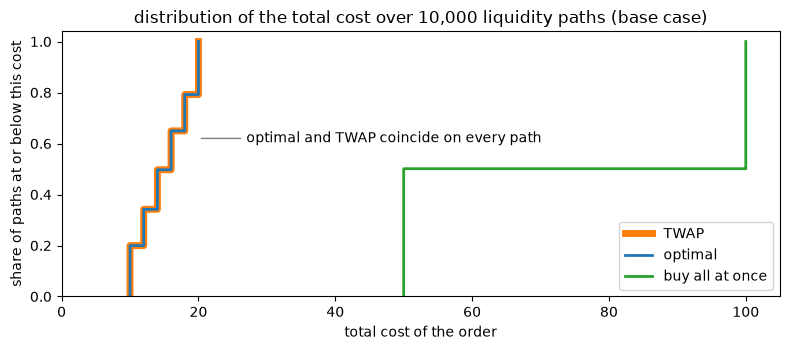

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for name in ("TWAP", "optimal", "buy all at once"):      # ax.ecdf: share of paths at or below each cost
    ax.ecdf(costs[name], color=POLICY_COLOR[name], label=name, linewidth=5 if name == "TWAP" else 2)
ax.set(xlabel="total cost of the order", ylabel="share of paths at or below this cost",
       xlim=(0, 105), ylim=(0, 1.04),
       title="distribution of the total cost over 10,000 liquidity paths (base case)")
ax.annotate("optimal and TWAP coincide on every path", xy=(20, 0.62), xytext=(27, 0.62), va="center",
            arrowprops={"arrowstyle": "-", "color": "gray"})
ax.legend(loc="lower right")
finish(fig, "cost_distribution")

**An empirical cumulative distribution gives the share of paths at or below each cost.** Optimal and TWAP coincide, with costs 10 to 20 in steps of 2. Buying immediately costs 50 if the first regime is high and 100 if it is low, each on about half the paths.

#### Checks

The next cell uses ratio 4, where actions depend on liquidity, to check agreement between the solver, simulator and environment:

1. exact evaluation recovers the computed values, and neither baseline has a higher value in any state;
2. the simulator and stepped environment agree on all $2^5=32$ possible liquidity paths;
3. the simulated mean is within four standard errors of the exact cost.

The paths are not equally probable: the simulated frequencies reflect the 0.8 persistence. Enumeration here checks path-by-path agreement, rather than estimating expected cost with an unweighted mean.

In [13]:
check = replace(BASE, liquidity=(1.0, 4.0))      # ratio 4, where the optimal trades depend on the regime
V_check, policy_check, _ = value_iteration(check)

# 1. The computed policy earns the values computed for it, and no baseline does better in any state.
assert np.abs(evaluate_policy(policy_check, check) - V_check).max() < 1e-12
for baseline in (twap_policy(check), immediate_policy(check)):
    assert (V_check >= evaluate_policy(baseline, check) - 1e-12).all()

# 2. The simulator and the environment give the same cost on each of the 32 possible liquidity paths.
all_paths = np.array(list(product((LOW, HIGH), repeat=check.n_periods)))
env = TradeExecutionEnv(check)
stepped = [rollout(env, policy_check, path)["cost"].sum() for path in all_paths]
assert np.allclose(run_policy(policy_check, all_paths, check), stepped, rtol=0, atol=1e-9)

# 3. The simulated mean cost is within 4 standard errors of the exact expected cost.
cost_check = run_policy(policy_check, paths, check)
standard_error = cost_check.std(ddof=1) / np.sqrt(len(cost_check))
assert abs(cost_check.mean() - expected_cost(V_check, check)) < 4 * standard_error

print("all checks passed")
print(f"ratio 4: exact expected cost {expected_cost(V_check, check):.4f} | "
      f"simulated mean {cost_check.mean():.4f} (standard error {standard_error:.4f})")

all checks passed
ratio 4: exact expected cost 11.8814 | simulated mean 11.9419 (standard error 0.0599)


### 4.4 Why adapting does not pay in the base case

The policy is free to trade more in liquid periods and less in illiquid ones, yet from the start it does not. To see why, we look at the first trade.

In [14]:
_, Q = bellman_backup(V, BASE)     # Q[5, 10, l, a]: value of buying a lots first, then trading optimally
print("expected cost of the whole order, by first trade")
print(f"start in high liquidity: 2 lots first {-Q[5, 10, HIGH, 2]:.4f} | "
      f"3 lots first {-Q[5, 10, HIGH, 3]:.4f}")
print(f"start in low liquidity:  2 lots first {-Q[5, 10, LOW, 2]:.4f} | "
      f"1 lot first  {-Q[5, 10, LOW, 1]:.4f}")

expected cost of the whole order, by first trade
start in high liquidity: 2 lots first 12.6944 | 3 lots first 12.8088
start in low liquidity:  2 lots first 17.3056 | 1 lot first  17.8296


**Moving one lot toward current high liquidity is not worthwhile in the base case.** The comparison changes only the first trade and follows the optimal policy afterward.

- **High first:** buying 3 rather than 2 costs 2.5 extra now. Later savings are only about 2.39, so expected total cost rises from 12.6944 to 12.8088.
- **Low first:** buying 1 rather than 2 saves 3 now, but adds about 3.52 later. Expected total cost rises from 17.3056 to 17.8296.

Whole-lot trades make these finite marginal changes consequential. Convex cost discourages uneven trades; with persistence 0.8, a liquid market today is also likely to remain liquid. The next comparison increases the liquidity contrast while keeping the original base case.

### 4.5 Sensitivity to the liquidity ratio

We repeat the comparison for liquidity ratios of 1, 2 and 4 on the same 10,000 paths.

In [15]:
def with_ratio(ratio):
    """The base case with high liquidity equal to `ratio` times low liquidity (low stays at 1)."""
    return replace(BASE, liquidity=(1.0, float(ratio)))


solved, exact_rows, simulated_rows = {}, {}, {}
for ratio in (1, 2, 4):
    params = with_ratio(ratio)
    V_r, policies_r, costs_r = solve_and_simulate(params, paths)
    solved[ratio] = (params, V_r, policies_r)
    exact_cost = {name: expected_cost(evaluate_policy(p, params), params) for name, p in policies_r.items()}
    assert abs(exact_cost["TWAP"] - (10 + 10 / ratio)) < 1e-9      # five 2-lot trades: 5 * 4 * E[1 / L]
    optimal = policies_r["optimal"]
    exact_rows[ratio] = {**exact_cost,
                         "reduction vs TWAP (%)": 100 * (1 - exact_cost["optimal"] / exact_cost["TWAP"]),
                         "first trade, low": optimal[5, 10, LOW], "first trade, high": optimal[5, 10, HIGH]}
    simulated_rows[ratio] = versus_twap(costs_r).loc["optimal"]

# With constant liquidity (ratio 1) many trades are equally good; the tie rule then takes the smaller one.
policy_1 = solved[1][2]["optimal"]
assert np.array_equal(policy_1[1:, :, LOW], np.floor(q_row / tau_column))
assert np.array_equal(policy_1[1:, :, HIGH], np.floor(q_row / tau_column))

# At ratio 4 the simulated saving agrees with the exact one, in size and in sign.
exact_saving_4 = exact_rows[4]["TWAP"] - exact_rows[4]["optimal"]
assert abs(simulated_rows[4]["mean saving per path"] - exact_saving_4) < 4 * simulated_rows[4]["std. error"]

print("exact expected cost, by liquidity ratio")
exact_table = pd.DataFrame(exact_rows).T.rename_axis("ratio")
display(exact_table.astype({"first trade, low": int, "first trade, high": int}))
print("optimal policy against TWAP on the 10,000 simulated paths, by liquidity ratio")
display(pd.DataFrame(simulated_rows).T.rename_axis("ratio"))

exact expected cost, by liquidity ratio


,optimal,TWAP,buy all at once,reduction vs TWAP (%),"first trade, low","first trade, high"
ratio,,,,,,
1,20.0000,20.0000,100.0000,0.0000,2,2
2,15.0000,15.0000,75.0000,0.0000,2,2
4,11.8814,12.5000,62.5000,4.9488,1,3


optimal policy against TWAP on the 10,000 simulated paths, by liquidity ratio


,simulated reduction vs TWAP (%),mean saving per path,std. error,share of paths cheaper,equal,more expensive
ratio,,,,,,
1,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
2,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
4,4.9191,0.6178,0.0191,0.5924,0.0000,0.4076


ratio 1: reached states where the regimes trade differently: 0, largest difference on a reached state: 0 lots
ratio 2: reached states where the regimes trade differently: 0, largest difference on a reached state: 0 lots
ratio 4: reached states where the regimes trade differently: 8, largest difference on a reached state: 2 lots


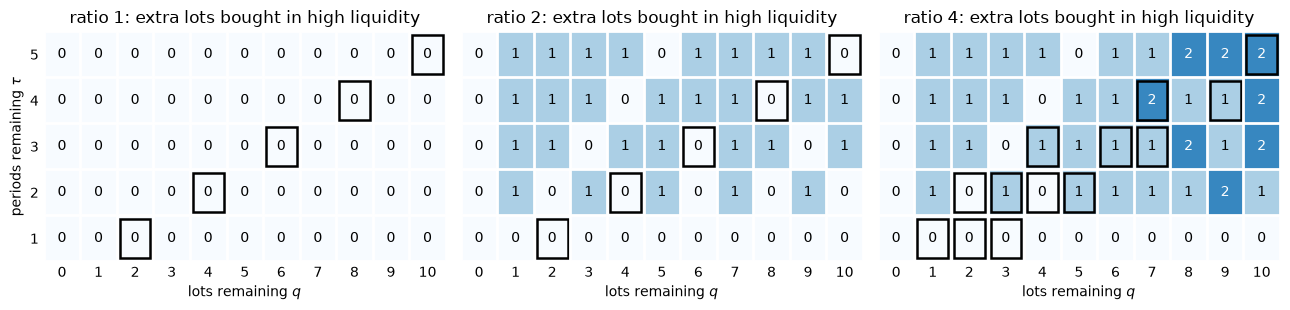

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (ratio, (params, _, policies_r)) in zip(axs, solved.items()):
    optimal = policies_r["optimal"]
    extra = optimal[:, :, HIGH] - optimal[:, :, LOW]
    assert (extra >= 0).all()
    visited = reached_states(optimal, params).any(axis=2)             # (tau, q) reached in either regime
    draw_grid(ax, extra, f"ratio {ratio}: extra lots bought in high liquidity", vmax=3, outline=visited)
    differ = extra[visited] > 0
    print(f"ratio {ratio}: reached states where the regimes trade differently: {int(differ.sum())}, "
          f"largest difference on a reached state: {int(extra[visited].max())} lots")
axs[0].set_ylabel(r"periods remaining $\tau$")
finish(fig, "ratio_sensitivity")

**Adaptation pays at ratio 4, but not at ratios 1 or 2.** Low liquidity stays at 1; only the high level changes.

- **Ratio 1:** constant liquidity makes equal splitting optimal, with expected cost 20.
- **Ratio 2:** the reached states remain identical to TWAP, with expected cost 15.
- **Ratio 4:** the first trade is 1 lot in low liquidity and 3 in high liquidity. Exact expected cost is 11.8814 versus TWAP's 12.5, a 4.9488% reduction; simulated reduction is 4.9191%.

The maps show high-regime trade minus low-regime trade. At ratio 4, 8 reached $(\tau,q)$ pairs have different actions, by up to 2 lots. Multiplying both liquidity levels by the same constant divides every cost by that constant without changing the percentage saving.

### 4.6 Expected saving and path-by-path risk

At ratio 4 the averages favor adaptation. The next figure shows the full cost distributions and the paired saving on each of the same 10,000 paths. Positive savings favor the optimal policy; negative savings mean TWAP was cheaper.

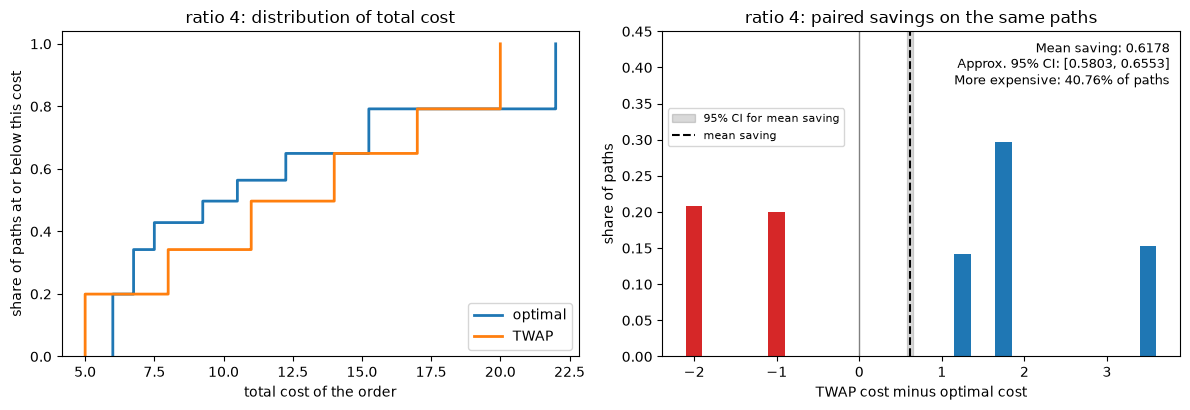

paired mean saving: 0.617825 | standard error: 0.019125
approximate 95% confidence interval for mean saving: [0.580341, 0.655309]
exact expected saving: 0.618600 | more expensive on 40.76% of paths


In [17]:
params_4, _, policies_4 = solved[4]
costs_4 = {name: run_policy(policies_4[name], paths, params_4) for name in ("optimal", "TWAP")}
saving_4 = costs_4["TWAP"] - costs_4["optimal"]  # positive means adaptation is cheaper on that path
mean_saving_4 = saving_4.mean()
se_saving_4 = saving_4.std(ddof=1) / np.sqrt(len(saving_4))
ci_saving_4 = mean_saving_4 + np.array([-1, 1]) * 1.96 * se_saving_4
costlier_share_4 = (saving_4 < -1e-9).mean()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for name, c in costs_4.items():
    axs[0].ecdf(c, color=POLICY_COLOR[name], label=name, linewidth=2)
axs[0].set(title="ratio 4: distribution of total cost", xlabel="total cost of the order",
           ylabel="share of paths at or below this cost", ylim=(0, 1.04))
axs[0].legend(loc="lower right")

saving_values, counts = np.unique(saving_4, return_counts=True)
axs[1].bar(saving_values, counts / len(saving_4), width=0.2,
           color=np.where(saving_values < 0, "tab:red", POLICY_COLOR["optimal"]))
axs[1].axvline(0, color="gray", linewidth=1)
axs[1].axvspan(*ci_saving_4, color="black", alpha=0.15, label="95% CI for mean saving")
axs[1].axvline(mean_saving_4, color="black", linestyle="--", label="mean saving")
axs[1].set(title="ratio 4: paired savings on the same paths", xlabel="TWAP cost minus optimal cost",
           ylabel="share of paths", ylim=(0, 0.45))
axs[1].text(0.98, 0.97,
            f"Mean saving: {mean_saving_4:.4f}\nApprox. 95% CI: [{ci_saving_4[0]:.4f}, {ci_saving_4[1]:.4f}]\n"
            f"More expensive: {costlier_share_4:.2%} of paths",
            transform=axs[1].transAxes, ha="right", va="top", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
axs[1].legend(loc="upper left", bbox_to_anchor=(0, 0.78), fontsize=8)
finish(fig, "ratio4_cost_distribution")

print(f"paired mean saving: {mean_saving_4:.6f} | standard error: {se_saving_4:.6f}")
print(f"approximate 95% confidence interval for mean saving: [{ci_saving_4[0]:.6f}, {ci_saving_4[1]:.6f}]")
print(f"exact expected saving: {exact_saving_4:.6f} | more expensive on {costlier_share_4:.2%} of paths")

**A positive average does not imply an improvement on every order.** The simulated mean saving is 0.6178 cost units, close to the exact 0.6186. Its approximate 95% confidence interval is [0.5803, 0.6553], entirely above zero. Red bars are the 40.76% of paths on which adaptation costs more than TWAP.

The interval is $\bar d \pm 1.96s_d/\sqrt{10{,}000}$, where $d$ is TWAP cost minus optimal cost **on the same path**. Paths are independent simulation replications even though regimes within a path are correlated. This normal approximation describes Monte Carlo uncertainty in the mean; it is not a range containing 95% of individual savings. The exact expected saving has no simulation uncertainty and depends on the assumed model.

## 5. Agent demonstration

**The computed policy is saved to `results/optimal_policy.csv` and read back before it acts in the environment**, so this section runs the stored policy, not the arrays still in memory. The file holds the optimal trade and the value of every state for liquidity ratios 1, 2 and 4.

In the first episode below the environment draws the liquidity itself from the seed. In the logs, *lots left* is the number of lots before the trade of that period.

In [18]:
records = []
for ratio, (_, V_r, policies_r) in solved.items():
    for tau, q, l in product(range(1, 6), range(11), (LOW, HIGH)):
        records.append({"liquidity_ratio": ratio, "periods_remaining": tau, "lots_remaining": q,
                        "regime": l, "trade": policies_r["optimal"][tau, q, l], "value": V_r[tau, q, l]})
pd.DataFrame(records).to_csv(RESULTS / "optimal_policy.csv", index=False, lineterminator="\n",
                             float_format="%.10g")


def load_policy(ratio):
    """Read the saved optimal policy for one liquidity ratio back into a table policy[tau, q, l]."""
    saved = pd.read_csv(RESULTS / "optimal_policy.csv")
    policy = np.zeros((BASE.n_periods + 1, BASE.n_lots + 1, 2), dtype=int)
    for row in saved[saved["liquidity_ratio"] == ratio].itertuples():
        policy[row.periods_remaining, row.lots_remaining, row.regime] = row.trade
    return policy


agent = load_policy(2)
assert np.array_equal(agent, policy)
print(f"one episode of the base case; the environment draws the liquidity itself (seed {SEED})")
display(rollout(TradeExecutionEnv(BASE), agent, seed=SEED).set_index("period"))

one episode of the base case; the environment draws the liquidity itself (seed 32020)


,liquidity,lots left,trade,cost
period,,,,
1,low,10,2,4.0000
2,low,8,2,4.0000
3,low,6,2,4.0000
4,high,4,2,2.0000
5,high,2,2,2.0000


base case (ratio 2), liquidity changes


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,high,10,2,2.0000,2,2.0000
2,high,8,2,2.0000,2,2.0000
3,low,6,2,4.0000,2,4.0000
4,low,4,2,4.0000,2,4.0000
5,high,2,2,2.0000,2,2.0000


ratio 4, liquidity changes


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,high,10,3,2.2500,2,1.0000
2,high,7,3,2.2500,2,1.0000
3,low,4,1,1.0000,2,4.0000
4,low,3,1,1.0000,2,4.0000
5,high,2,2,1.0000,2,1.0000


ratio 4, liquidity stays low


,liquidity,lots left,trade,cost,TWAP trade,TWAP cost
period,,,,,,
1,low,10,1,1.0000,2,4.0000
2,low,9,2,4.0000,2,4.0000
3,low,7,2,4.0000,2,4.0000
4,low,5,2,4.0000,2,4.0000
5,low,3,3,9.0000,2,4.0000


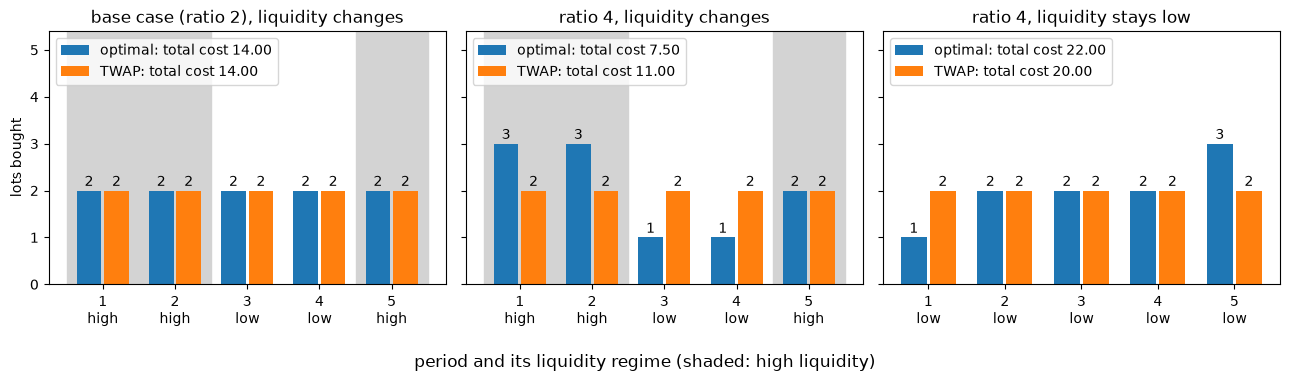

In [19]:
def plot_episode(ax, logs, title):
    """Lots bought per period by each policy on one liquidity path. Shaded periods have high liquidity."""
    periods = np.arange(1, 6)
    regimes = logs["TWAP"]["liquidity"].to_numpy()
    for t in periods[regimes == "high"]:
        ax.axvspan(t - 0.5, t + 0.5, color="lightgray")
    for shift, (name, log) in zip((-0.19, 0.19), logs.items()):
        trades = log.set_index("period")["trade"].reindex(periods, fill_value=0)
        bars = ax.bar(periods + shift, trades, width=0.34, color=POLICY_COLOR[name],
                      label=f"{name}: total cost {log['cost'].sum():.2f}")
        ax.bar_label(bars, padding=1)
    tick_labels = [f"{t}\n{r}" for t, r in zip(periods, regimes)]
    ax.set(title=title, xticks=periods, xticklabels=tick_labels, ylim=(0, 5.4))
    ax.legend(loc="upper left")


episodes = [("base case (ratio 2), liquidity changes", 2, [HIGH, HIGH, LOW, LOW, HIGH]),
            ("ratio 4, liquidity changes", 4, [HIGH, HIGH, LOW, LOW, HIGH]),
            ("ratio 4, liquidity stays low", 4, [LOW, LOW, LOW, LOW, LOW])]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (title, ratio, path) in zip(axs, episodes):
    env = TradeExecutionEnv(with_ratio(ratio))
    logs = {"optimal": rollout(env, load_policy(ratio), path),
            "TWAP": rollout(env, twap_policy(env.params), path)}
    plot_episode(ax, logs, title)
    print(title)
    table = logs["optimal"].set_index("period")
    table["TWAP trade"] = logs["TWAP"]["trade"].to_numpy()
    table["TWAP cost"] = logs["TWAP"]["cost"].to_numpy()
    display(table)
axs[0].set_ylabel("lots bought")
fig.supxlabel("period and its liquidity regime (shaded: high liquidity)")
finish(fig, "episodes")

**The saved policy completes the order in the environment.** The seeded base-case run buys 2 lots each period and costs 16. The figure compares optimal and TWAP on identical paths:

- **Ratio 2, changing liquidity:** both buy 2 each period and cost 14.
- **Ratio 4, the same changing path:** optimal buys $(3,3,1,1,2)$ and costs 7.50, versus TWAP's 11.00.
- **Ratio 4, liquidity stays low:** optimal waits by buying only 1 initially and must buy 3 at the end. It costs 22 versus TWAP's 20, illustrating the downside in section 4.6.

## 6. Requirements

In [20]:
print("operating system:", platform.system(), platform.release(), platform.machine())
print("python:", platform.python_version())
for package in ("numpy", "pandas", "matplotlib", "gymnasium", "ipykernel"):
    print(f"{package}: {version(package)}")

operating system: Darwin 27.2.0 arm64
python: 3.12.15
numpy: 2.5.5
pandas: 3.1.1
matplotlib: 3.11.2
gymnasium: 1.4.0
ipykernel: 7.4.0


The cell above records OS, Python and imported package versions for this run. The notebook needs no GPU, data download or environment display window.

```
git clone https://github.com/ahmedas91/rl-optimal-trade-execution.git
cd rl-optimal-trade-execution
uv sync
uv run jupyter lab optimal_trade_execution.ipynb
```

`uv sync` uses Python 3.12 and `uv.lock`. Alternatively, create a Python 3.12 virtual environment, install `requirements.txt` and launch JupyterLab (commands in the README). Run all cells from the top; the notebook rewrites both CSVs and seven figures, using seed 32020.

Supporting source is collapsed using JupyterLab cell metadata; expand a cell to inspect or edit it. All code and outputs remain in this notebook. Follow the timed route at the start and `presentation_notes.md` for the presentation and technical questions.

## 7. Conclusions

**Key findings**

1. **The base-case answer is no.** Optimal and TWAP both have expected cost 15 and buy 2 lots in every period on every path. Regime-dependent actions exist only outside the reached trajectory.
2. **A stronger liquidity contrast changes the decision.** At ratio 4, adaptation lowers exact expected cost from 12.5 to 11.8814, a 4.95% reduction (4.92% in simulation).
3. **Expected improvement includes pathwise risk.** The mean simulated saving is 0.6178, with an approximate 95% confidence interval of [0.5803, 0.6553], yet the policy costs more on 40.8% of paths. The interval quantifies uncertainty in the mean, not a guarantee about an individual order.
4. **Splitting matters more than adapting in these comparisons.** In the base case it reduces expected cost from 75 for buying immediately to 15 for TWAP. This echoes the Week 5 lab's distinction between the large benefit of splitting and the smaller benefit of reacting to information.

**Challenges encountered and lessons learned**

- **Explaining a null result:** the policy heatmaps initially suggest adaptation, but reachability shows why it cannot help this starting order. Judge performance from the specified start distribution, not from differences in unused states.
- **Understanding whole-lot decisions:** convex impact, integer actions and persistent liquidity make a one-lot adjustment too costly in the base case. A regime-dependent cost alone does not guarantee a different optimal trade.
- **Separating expectation from realization:** exact evaluation establishes the model's expected benefit; paired simulations reveal its dispersion and downside. A confidence interval for the average is not a prediction interval for one path.
- **Using the finite horizon:** time in the state makes transitions acyclic. Five synchronous sweeps settle all decision layers and a sixth confirms the stopping rule, even with discount factor 1.

**Limitations**

The conclusions concern a small, known model: constant prices, temporary quadratic impact, perfectly observed exogenous liquidity and normalized costs. Only the liquidity ratio is varied; persistence, horizon and lot size remain fixed. Real execution would require calibrated dynamics, price and order-book risk, and potentially a different representation or learning method.

## References

1. Almgren, R. (2012). Optimal trading with stochastic liquidity and volatility. *SIAM Journal on Financial Mathematics*, 3(1), 163–181. https://doi.org/10.1137/090763470
2. Almgren, R., & Chriss, N. (2001). Optimal execution of portfolio transactions. *The Journal of Risk*, 3(2), 5–39. https://doi.org/10.21314/JOR.2001.041
3. Bertsimas, D., & Lo, A. W. (1998). Optimal control of execution costs. *Journal of Financial Markets*, 1(1), 1–50. https://doi.org/10.1016/S1386-4181(97)00012-8
4. Cheridito, P., & Sepin, T. (2014). Optimal trade execution under stochastic volatility and liquidity. *Applied Mathematical Finance*, 21(4), 342–362. https://doi.org/10.1080/1350486X.2014.881005
5. Nevmyvaka, Y., Feng, Y., & Kearns, M. (2006). Reinforcement learning for optimized trade execution. *Proceedings of the 23rd International Conference on Machine Learning*, 673–680. https://doi.org/10.1145/1143844.1143929
6. Puterman, M. L. (1994). *Markov Decision Processes: Discrete Stochastic Dynamic Programming*. Wiley. https://doi.org/10.1002/9780470316887 (Chapter 4, Finite-Horizon Markov Decision Processes.)
7. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. (Section 4.4, Value Iteration.)
8. Towers, M., Kwiatkowski, A., Balis, J., et al. (2025). Gymnasium: A standard interface for reinforcement learning environments. *Advances in Neural Information Processing Systems 38*, 163114–163129. https://doi.org/10.52202/085713-4916
9. Azeredo, F. (2026). *Lab exercise 03: Optimal control of execution costs*. ADSP 32020 Reinforcement Learning, Week 5 course materials, University of Chicago.
10. Rao, A., & Jelvis, T. *Foundations of Reinforcement Learning with Applications in Finance*, Chapter 9, [optimal order execution example](https://github.com/TikhonJelvis/RL-book/blob/master/rl/chapter9/optimal_order_execution.py). Conceptual background cited in the proposal.

**Code.** All the code is in this notebook and was written for this project. It uses NumPy, pandas, Matplotlib and Gymnasium, and no code from external repositories. Repository of this project: https://github.com/ahmedas91/rl-optimal-trade-execution

## Use of generative AI

Claude (Anthropic, through Claude Code) assisted with drafting the code, checks, figures, commentary and README on November 17–18, 2026, using the group's project proposal.